# WaveHolo demo: record a synthetic hologram, then measure its focus

Everything below is **simulated** with `wave_hologram.py` itself; nothing here is a
hardware or biology result. The notebook shows the default pipeline from the README:

1. build an object and propagate it to a sensor (`angular_spectrum`),
2. record an off-axis hologram with an **unknown reference phase** and a **fractional
   carrier** (`record_hologram`),
3. estimate the carrier from the hologram (`estimate_carrier_2d`) and reconstruct the field
   (`reconstruct_field`),
4. find the focus with `find_focus` (coarse sweep + golden-section refinement of *realness*),
5. look at the reconstructed intensity and phase.

`wave_hologram` is a single flat module, not a PyPI package. Run this notebook from the repository
(`pip install -e ".[notebook]"` or just open it in `examples/`). No function needed adapting.

In [1]:
import os, sys
try:
    import wave_hologram as W
except ImportError:                       # not installed: use the repository copy
    sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))
    import wave_hologram as W
import numpy as np
import matplotlib.pyplot as plt

print("wave_hologram", W.__version__, "| numpy", np.__version__)

wave_hologram 0.1.3 | numpy 2.5.4


## 1. A synthetic hologram

The object is the repo's own test pattern (a ring, a cross and three dots) at a true distance of
5.000 mm from the sensor. The reference beam gets a piston of 1.2 rad and a carrier of 80.37 bins:
both are *unknown* to the pipeline.

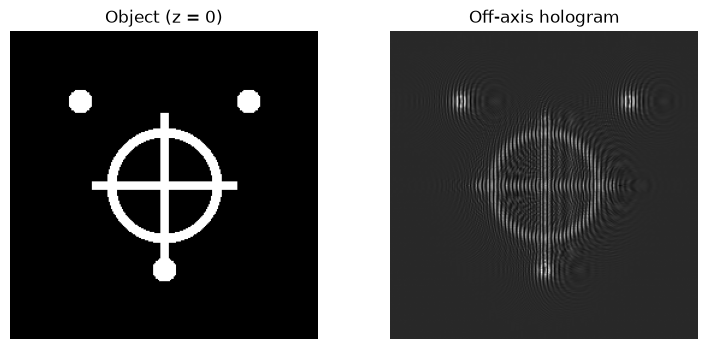

In [2]:
z_obj = 5.0e-3
obj = W.make_object()
sensor = W.angular_spectrum(obj.astype(complex), z_obj)
holo = W.record_hologram(sensor, car=80.37, ref_phase=1.2)

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(obj, cmap="gray"); ax[0].set_title("Object (z = 0)")
ax[1].imshow(holo, cmap="gray"); ax[1].set_title("Off-axis hologram")
for a in ax: a.axis("off")
plt.show()

## 2. Carrier, reconstruction, focus

The carrier is estimated from the hologram (sub-bin precision). `find_focus` then sweeps −10…0 mm in
101 coarse steps and refines the minimum of *realness* (invariant to the unknown reference phase).

In [3]:
carrier = W.estimate_carrier_2d(holo, dc_radius=30.0 / W.N)
field0 = W.reconstruct_field(holo, carrier=carrier)

sweep = np.linspace(-10e-3, 0.0, 101)
res = W.find_focus(field0, sweep, metric="realness")

print(f"estimated carrier (ky, kx): ({carrier[0]:+.4f}, {carrier[1]:+.4f}) bins   (true: (0, -80.37))")
print(f"truth    : {-z_obj*1e3:+.4f} mm")
print(f"measured : {res['z']*1e3:+.4f} mm   error {abs(res['z'] + z_obj)*1e6:.1f} um   contrast {res['contrast']:.1f}x")

estimated carrier (ky, kx): (+0.0025, -80.3850) bins   (true: (0, -80.37))
truth    : -5.0000 mm
measured : -4.9980 mm   error 2.0 um   contrast 2.9x


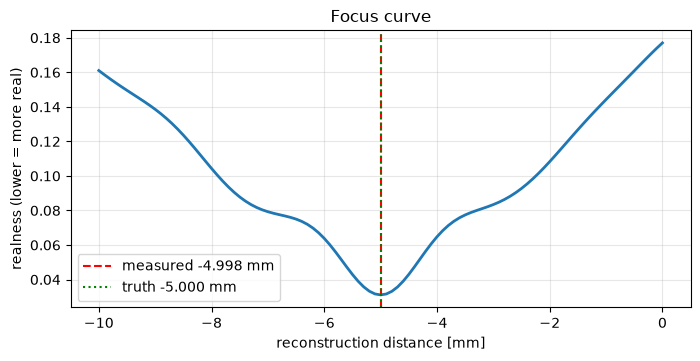

In [4]:
plt.figure(figsize=(8, 3.6))
plt.plot(sweep * 1e3, res["curve"], lw=2)
plt.axvline(res["z"] * 1e3, color="r", ls="--", label=f"measured {res['z']*1e3:+.3f} mm")
plt.axvline(-z_obj * 1e3, color="g", ls=":", label=f"truth {-z_obj*1e3:+.3f} mm")
plt.xlabel("reconstruction distance [mm]"); plt.ylabel("realness (lower = more real)")
plt.title("Focus curve"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 3. Reconstructed intensity and phase at the measured focus

The recovered phase carries the unknown reference piston as a constant offset, so only phase
*differences* are meaningful. The correlation is the one the README quotes for this scene.

correlation of |U|^2 with the true object: 0.956


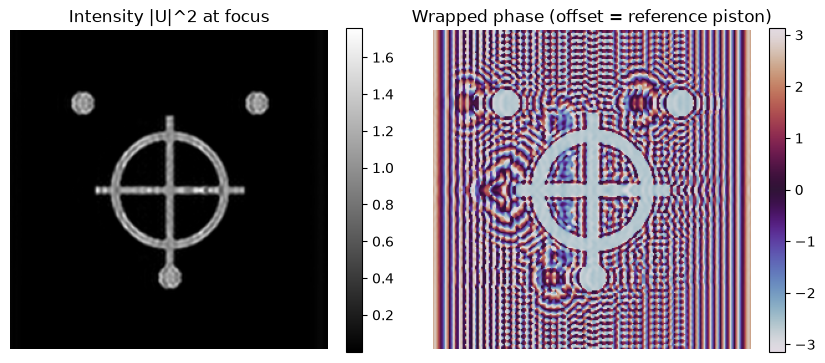

In [5]:
best = W.angular_spectrum(field0, res["z"])
print(f"correlation of |U|^2 with the true object: {W.correlation(np.abs(best)**2, obj):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.4))
im0 = ax[0].imshow(np.abs(best) ** 2, cmap="gray"); ax[0].set_title("Intensity |U|^2 at focus")
im1 = ax[1].imshow(np.angle(best), cmap="twilight", vmin=-np.pi, vmax=np.pi)
ax[1].set_title("Wrapped phase (offset = reference piston)")
fig.colorbar(im0, ax=ax[0], fraction=0.046); fig.colorbar(im1, ax=ax[1], fraction=0.046)
for a in ax: a.axis("off")
plt.show()

## 4. A phase object: why the metric matters

A transparent object (binary phase of π/2) changes the phase, not the brightness. Below, the same
pipeline is run on it with `realness` and with `ac_realness`, plus a plain intensity-variance maximum
for comparison. This is one scene, not a benchmark; the README's S7 study covers 12 objects.

In [6]:
pobj = np.exp(1j * (np.pi / 2) * W.make_object())
psensor = W.angular_spectrum(pobj, z_obj)
pholo = W.record_hologram(psensor, car=80.37, ref_phase=1.2)
pf0 = W.reconstruct_field(pholo, carrier=W.estimate_carrier_2d(pholo, dc_radius=30.0 / W.N))

prop = W.Propagator(pf0)
var_curve = np.array([np.var(np.abs(prop(d)) ** 2) for d in sweep])
rows = [("realness", W.find_focus(pf0, sweep, metric="realness")["z"]),
        ("ac_realness", W.find_focus(pf0, sweep, metric="ac_realness")["z"]),
        ("max intensity variance", sweep[int(np.argmax(var_curve))])]
print(f"truth: {-z_obj*1e3:+.3f} mm")
for name, z in rows:
    print(f"{name:>24}: {z*1e3:+8.3f} mm   error {abs(z + z_obj)*1e3:7.3f} mm")

truth: -5.000 mm
                realness:  -10.000 mm   error   5.000 mm
             ac_realness:   -4.935 mm   error   0.065 mm
  max intensity variance:   -1.400 mm   error   3.600 mm


Read this honestly: it is a single synthetic scene with one noise-free hologram. The repository's
real-data check (530 holograms from the Cuenat et al. DHM dataset, 6 of 100 stage positions) tests
the **slope** of focus against stage position, not absolute focus. See `README.md` and
`RESULTS_v0.1.3.md` for the limits.